# Lista 5: A atenção por dentro
**Caderno de atividades do Capítulo 5** | **A ginga dos números**, livro de exercícios | Professor Bruno Menezes | [repositório](https://github.com/brunoleomenezes/ginga-dos-numeros)

Nome: ______________________  Turma: ______________

O código de cada exercício já está nas células, com a saída visível, para você conferir. O ideal é **digitar** o código em um caderno seu, como pede a Lista em PDF, e usar este caderno para comparar. Execute as células **na ordem**: quase todas dependem das anteriores. Em caso de dúvida, use *Ambiente de execução > Reiniciar sessão e executar tudo*.

## Parte 1. Seis ferramentas novas de Python

### B1. Softmax por linha: exp, sum e axis

O softmax transforma pontuações em pesos que somam 1: eleva-se e a cada pontuação e divide-se pela soma. Com NumPy, **np.exp** faz isso em todos os números de uma vez, e **axis=1**, junto com **keepdims=True**, soma cada linha de uma tabela sem perder o formato.

In [1]:
# "import" carrega uma biblioteca; NumPy faz contas com tabelas de números, apelidado de np
import numpy as np

# np.array cria uma matriz (tabela de números): aqui, 2 linhas de pontuações com 3 números cada
pontuacoes = np.array([[2.0, 1.0, 0.0],
                       [0.0, 0.0, 0.0]])

# np.exp aplica a exponencial (e elevado a x) a cada número; o resultado é sempre positivo
e = np.exp(pontuacoes)
# Divide cada número pela soma da sua linha (axis=1), para os pesos somarem 1: é o softmax.
# keepdims=True guarda a soma como coluna, o que permite dividir a tabela inteira de uma vez
pesos = e / e.sum(axis=1, keepdims=True)

# print mostra o resultado na tela; .round(4) arredonda para 4 casas decimais
print(pesos.round(4))
# Soma cada linha dos pesos para conferir que cada uma dá 1
print("soma de cada linha:", pesos.sum(axis=1))

[[0.6652 0.2447 0.09  ]
 [0.3333 0.3333 0.3333]]
soma de cada linha: [1. 1.]


Cada linha da tabela virou um conjunto de pesos que soma 1. A segunda linha, toda de zeros, deu pesos iguais. O keepdims=True mantém a soma como uma coluna, e é isso que permite dividir a tabela inteira de uma vez.

**SUA VEZ**

1. Multiplique as pontuações por 10 e refaça. O que acontece com os pesos da primeira linha?
2. Divida as pontuações por 10 e refaça. Os pesos ficam mais concentrados ou mais parecidos?

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [2]:
# Espaço para os seus testes

### B2. Matrizes: formato, transposta e produto com @

Quase toda a atenção é multiplicação de matrizes. O **.shape** mostra o formato (linhas, colunas), o **.T** troca linhas por colunas e o **@** multiplica. Para multiplicar A por B, o número de colunas de A deve ser igual ao de linhas de B.

In [3]:
# Matriz X com 2 linhas e 3 colunas (uma lista de listas vira uma tabela)
X = np.array([[1.0, 0.0, 2.0],
              [0.0, 1.0, 1.0]])
# Matriz W com 3 linhas e 2 colunas
W = np.array([[1.0, 0.0],
              [0.0, 1.0],
              [1.0, 1.0]])

# .shape dá o formato (linhas, colunas) de cada matriz
print("X:", X.shape, " W:", W.shape)
# Escreve um título antes de mostrar o produto
print("X @ W:")
# O operador @ multiplica matrizes: as 3 colunas de X casam com as 3 linhas de W
print(X @ W)
# Uma 2x3 vezes uma 3x2 dá uma 2x2 (linhas de X, colunas de W)
print("formato de X @ W:", (X @ W).shape)
# .T é a transposta: troca linhas por colunas, então a 3x2 vira 2x3
print("W.T tem formato", W.T.shape)

X: (2, 3)  W: (3, 2)
X @ W:
[[3. 2.]
 [1. 2.]]
formato de X @ W: (2, 2)
W.T tem formato (2, 3)


Uma matriz 2x3 vezes uma 3x2 dá uma 2x2. Cada linha de X @ W é a soma ponderada das linhas de W, com os pesos vindos da linha correspondente de X.

**SUA VEZ**

1. Tente calcular W @ X. O que o Python diz? Por quê?
2. Calcule X @ W.T e veja o formato do resultado.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [4]:
# Espaço para os seus testes

### B3. Máscara: np.tril e np.where

A máscara causal é um triângulo de uns. O **np.tril** cria um triângulo inferior (uns na diagonal e abaixo) e o **np.where(condição, a, b)** escolhe, posição a posição, entre dois valores. Usaremos −∞ (**-np.inf**) para proibir uma posição antes do softmax.

In [5]:
# np.ones((4, 4)) cria uma tabela 4x4 de uns; np.tril zera tudo acima da diagonal.
# Fica um triângulo: a máscara causal (cada posição só enxerga a si e às anteriores)
mascara = np.tril(np.ones((4, 4)))
# Mostra a máscara triangular
print(mascara)

# np.arange(16) gera 0, 1, ..., 15 (como decimais) e reshape(4, 4) os arruma em 4 linhas
S = np.arange(16, dtype=float).reshape(4, 4)
# np.where escolhe posição a posição: onde a máscara é 1 fica S, onde é 0 fica menos infinito
S_mascarada = np.where(mascara > 0, S, -np.inf)
# Mostra as pontuações com as posições proibidas trocadas por -inf
print(S_mascarada)
# e elevado a menos infinito dá 0: peso zero para o que a máscara proíbe
print("exp(-inf) =", np.exp(-np.inf))

[[1. 0. 0. 0.]
 [1. 1. 0. 0.]
 [1. 1. 1. 0.]
 [1. 1. 1. 1.]]
[[  0. -inf -inf -inf]
 [  4.   5. -inf -inf]
 [  8.   9.  10. -inf]
 [ 12.  13.  14.  15.]]
exp(-inf) = 0.0


Onde a máscara vale 0, o valor virou −∞. E e elevado a menos infinito dá zero, que é o que queremos: peso zero para as posições proibidas.

**SUA VEZ**

1. Crie uma máscara 5x5 e confirme que a primeira linha só tem um 1.
2. Troque np.tril por np.triu e veja que posições ficam livres.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [6]:
# Espaço para os seus testes

### B4. Juntar, fatiar e cortar negativos

Com várias cabeças, as saídas são coladas lado a lado: **np.hstack**. Para pegar colunas, use fatias como **M[:, :2]**. A ativação ReLU, que corta os negativos, é **np.maximum(x, 0)**.

In [7]:
# Duas matrizes 2x2 para juntar (como as saídas de duas cabeças de atenção)
a = np.array([[1.0, 2.0], [3.0, 4.0]])
# A segunda matriz tem um número negativo, para testar a ReLU
b = np.array([[0.5, -1.0], [0.0, 9.0]])

# np.hstack cola as matrizes lado a lado (precisam ter o mesmo número de linhas)
junto = np.hstack([a, b])
# Mostra a matriz 2x4 resultante
print(junto)
# Título da próxima saída
print("duas primeiras colunas:")
# Fatia [:, :2]: ":" pega todas as linhas e ":2" as colunas 0 e 1 (o 2 fica de fora)
print(junto[:, :2])
# Título da próxima saída
print("ReLU de b:")
# np.maximum(b, 0) fica com o maior entre cada número e 0: corta os negativos (a ReLU)
print(np.maximum(b, 0))

[[ 1.   2.   0.5 -1. ]
 [ 3.   4.   0.   9. ]]
duas primeiras colunas:
[[1. 2.]
 [3. 4.]]
ReLU de b:
[[0.5 0. ]
 [0.  9. ]]


O hstack une as matrizes lado a lado (mesmo número de linhas). A fatia [:, :2] pega todas as linhas e as duas primeiras colunas. O maximum compara cada número com 0 e fica com o maior.

**SUA VEZ**

1. Pegue só as duas últimas colunas de junto.
2. Aplique a ReLU a junto - 2 e veja quais números sobraram.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [8]:
# Espaço para os seus testes

### B5. Média e variância por linha (normalização)

A normalização do bloco subtrai a média de cada vetor e divide pelo desvio-padrão. Com NumPy: **mean(axis=1, keepdims=True)**, **var(axis=1, keepdims=True)** e a raiz com **np.sqrt**.

In [9]:
# Dois vetores (linhas) com escalas bem diferentes
v = np.array([[1.0, 2.0, 3.0, 6.0],
              [10.0, 10.0, 10.0, 14.0]])

# mean(axis=1) calcula a média de cada linha; keepdims=True a guarda como coluna
media = v.mean(axis=1, keepdims=True)
# var(axis=1) calcula a variância de cada linha (o quanto os números se espalham)
var = v.var(axis=1, keepdims=True)
# Subtrai a média e divide pelo desvio-padrão (raiz da variância); o 1e-5 (0,00001)
# evita divisão por zero quando todos os números da linha são iguais
z = (v - media) / np.sqrt(var + 1e-5)

# Mostra os vetores normalizados
print(z.round(4))
# Confere que a média de cada linha ficou 0 (o "-0." é só um zero com sinal de arredondamento)
print("média de cada linha:", z.mean(axis=1).round(4))
# Confere que a variância de cada linha ficou (quase) 1
print("variância de cada linha:", z.var(axis=1).round(4))

[[-1.069  -0.5345  0.      1.6036]
 [-0.5773 -0.5773 -0.5773  1.732 ]]
média de cada linha: [-0.  0.]
variância de cada linha: [1. 1.]


Depois da normalização, cada linha tem média 0 e variância (quase) 1, mesmo que as linhas originais tivessem escalas muito diferentes. O 1e-5 evita dividir por zero em um vetor de números iguais.

**SUA VEZ**

1. Teste a normalização em [5, 5, 5, 5]. Por que o 1e-5 é necessário?
2. Multiplique a primeira linha por 100 e normalize de novo. O resultado muda?

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [10]:
# Espaço para os seus testes

### B6. Mapa de calor com imshow

A matriz de atenção é desenhada como um mapa de calor: quanto mais escuro, maior o peso. O **plt.imshow** faz o desenho, e o **plt.text** escreve o número em cada célula.

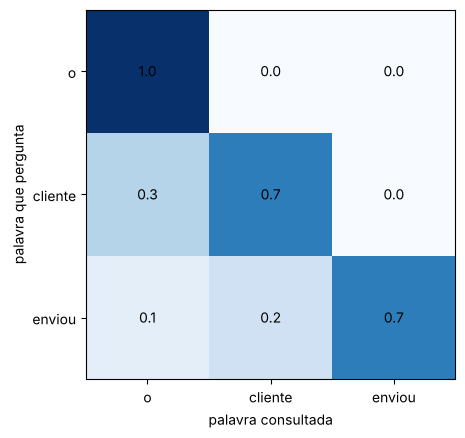

In [11]:
# Matplotlib desenha gráficos; o módulo pyplot é apelidado de plt
import matplotlib.pyplot as plt

# Uma matriz de atenção de exemplo: cada linha soma 1 e acima da diagonal é tudo zero
M = np.array([[1.0, 0.0, 0.0],
              [0.3, 0.7, 0.0],
              [0.1, 0.2, 0.7]])
# Lista de textos (strings) com as palavras de cada linha e coluna
palavras = ["o", "cliente", "enviou"]

# plt.imshow pinta a matriz como mapa de calor, em tons de azul, com cores de 0 a 1
plt.imshow(M, cmap="Blues", vmin=0, vmax=1)
# Põe as palavras como rótulos das 3 colunas (range(3) gera 0, 1, 2)
plt.xticks(range(3), palavras)
# Põe as palavras como rótulos das 3 linhas
plt.yticks(range(3), palavras)
# Laço for: repete o bloco recuado para cada linha i (0, 1, 2)
for i in range(3):
    # Laço dentro do laço: para cada coluna j da linha i
    for j in range(3):
        # Escreve o peso no centro da célula; f-string com :.1f mostra 1 casa decimal.
        # Atenção: plt.text recebe primeiro a coluna (j, eixo x) e depois a linha (i, eixo y)
        plt.text(j, i, f"{M[i, j]:.1f}", ha="center", va="center")
# Nome do eixo horizontal (colunas)
plt.xlabel("palavra consultada")
# Nome do eixo vertical (linhas)
plt.ylabel("palavra que pergunta")
# Mostra a figura
plt.show()

Cada linha é uma palavra que pergunta, e cada coluna é uma palavra consultada. A linha de cima só enxerga a si mesma, como em uma máscara causal.

**SUA VEZ**

1. Troque o cmap por "Oranges" e veja a diferença.
2. Acrescente uma quarta palavra, "a", e uma quarta linha e coluna à matriz.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [12]:
# Espaço para os seus testes

## Parte 2. Os dez exercícios do capítulo

### Exercício 1. O verbo está a quatro palavras do sujeito
*Exemplo 1 do capítulo*

Vamos reproduzir a conta que mostra por que olhar só a palavra anterior não basta, e por que alongar o contexto explode o número de casos.

In [13]:
# Biblioteca de matemática do Python (não é usada nesta célula)
import math
# Counter é um dicionário que conta quantas vezes cada coisa aparece
from collections import Counter

# Lista com as 4 frases do mini-corpus (o texto de onde o modelo aprende)
corpus = ["o cliente da filial de Resende enviou a nota",
          "os clientes da filial de Resende enviaram a nota",
          "o cliente da filial de Niterói enviou a guia",
          "os clientes da filial de Niterói enviaram a guia"]

# "def" cria uma função: conta que palavras vêm logo depois de um contexto (lista de palavras)
def proximas(contexto):
    # len dá o tamanho do contexto, k palavras
    k = len(contexto)
    # Começa um contador vazio
    c = Counter()
    # Percorre cada frase do corpus
    for frase in corpus:
        # .split() quebra a frase nos espaços, gerando a lista de palavras
        t = frase.split()
        # Percorre cada posição de onde ainda cabe um contexto de k palavras e a seguinte
        for i in range(len(t) - k):
            # A fatia t[i:i + k] pega k palavras a partir de i; compara com o contexto
            if t[i:i + k] == contexto:
                # Se bateu, soma 1 para a palavra que vem logo depois
                c[t[i + k]] += 1
    # "return" devolve o contador como resultado da função
    return c

# Testa três contextos, de 1, 3 e 5 palavras, todos terminando em "Resende"
for ctx in (["Resende"], ["filial", "de", "Resende"], ["cliente", "da", "filial", "de", "Resende"]):
    # Conta as palavras seguintes para este contexto
    c = proximas(ctx)
    # Soma todas as contagens: é o total de vezes que o contexto apareceu
    total = sum(c.values())
    # " ".join junta as palavras do contexto com espaços, para imprimir
    print(" ".join(ctx))
    # Percorre os pares (palavra, contagem) em ordem alfabética (sorted)
    for palavra, n in sorted(c.items()):
        # Probabilidade = contagem dividida pelo total; :.2f mostra 2 casas
        print(f"   P({palavra} | contexto) = {n}/{total} = {n / total:.2f}")

Resende
   P(enviaram | contexto) = 1/2 = 0.50
   P(enviou | contexto) = 1/2 = 0.50
filial de Resende
   P(enviaram | contexto) = 1/2 = 0.50
   P(enviou | contexto) = 1/2 = 0.50
cliente da filial de Resende
   P(enviou | contexto) = 1/1 = 1.00


Olhando só "Resende", ou até as três últimas palavras, o modelo tira cara ou coroa entre "enviou" e "enviaram". Só o contexto de cinco palavras, que inclui "cliente", decide.

In [14]:
# set guarda cada palavra uma vez só; a compreensão percorre todas as palavras de todas as
# frases. V é o tamanho do vocabulário (aqui V é um número; no Exercício 2 vira uma matriz)
V = len(set(w for f in corpus for w in f.split()))
# Mostra quantas palavras distintas existem
print("palavras distintas no corpus:", V)
# print vazio pula uma linha
print()
# Cabeçalho da tabela
print("k   contextos possíveis (V)   contextos possíveis (50.000 palavras)")
# Para cada tamanho de contexto k
for k in (1, 2, 3, 5):
    # V ** k é V elevado a k (as combinações possíveis); :>16, alinha à direita com vírgula
    # de milhar, e .replace troca a vírgula por ponto, como se escreve no Brasil
    print(f"{k}   {V ** k:>16,}   {50000 ** k:>34,}".replace(",", "."))

palavras distintas no corpus: 14

k   contextos possíveis (V)   contextos possíveis (50.000 palavras)
1                 14                               50.000
2                196                        2.500.000.000
3              2.744                  125.000.000.000.000
5            537.824      312.500.000.000.000.000.000.000


Com 14 palavras, os contextos de tamanho 5 já passam de meio milhão. Com um vocabulário real, passam de 10 elevado a 23. É por isso que a atenção aprende uma regra de consulta, e não uma tabela de contextos.

**SUA VEZ**

1. Acrescente ao corpus a frase "o cliente da filial de Resende enviou a guia" e refaça a primeira parte. O que muda para o contexto "Resende"?
2. Explique, com suas palavras, por que o contexto de cinco palavras resolve o problema mas não escala.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [15]:
# Espaço para os seus testes

### Exercício 2. Cada palavra vira uma consulta, uma chave e um valor
*Exemplo 2 do capítulo*

Vamos montar as entradas, as três matrizes de pesos e calcular consulta, chave e valor de cada palavra. Os pesos são **fixados à mão**, como no capítulo.

In [16]:
# As cinco palavras da frase
tokens = ["o", "cliente", "enviou", "a", "nota"]
# traços: artigo, pessoa, ação, coisa
# Matriz E: cada linha é o vetor de uma palavra, com 4 traços fixados à mão
E = np.array([[1, 0,   0,   0.5],  # o
              [0, 1,   0.5, 0  ],  # cliente
              [0, 0.5, 1,   0  ],  # enviou
              [1, 0,   0.5, 0  ],  # a
              [0, 0,   0.5, 1  ]]) # nota

# Pesos da consulta (4x2): transformam os 4 traços em uma pergunta de 2 números
Wq1 = np.array([[1.5, 0], [0.5, 2], [0, 1.5], [2, 0]])
# Pesos da chave (4x2): o "rótulo" que cada palavra oferece para ser encontrada
Wk1 = np.array([[0, 0], [0, 2], [2, 1.5], [0, 0.5]])
# Pesos do valor (4x2): o conteúdo que a palavra entrega; dtype=float pede decimais
Wv1 = np.array([[0, 0], [0, 1], [1, 0], [0, 1]], dtype=float)

# Consultas de todas as palavras de uma vez: cada linha de E vezes Wq1
Q = E @ Wq1
# Chaves de todas as palavras
K = E @ Wk1
# Valores de todas as palavras (V deixa de ser o tamanho do vocabulário)
V = E @ Wv1

# Cabeçalho da tabela
print("palavra    q                k                v")
# enumerate devolve a posição i e a palavra t ao mesmo tempo
for i, t in enumerate(tokens):
    # :8s reserva 8 espaços para a palavra; Q[i] é a linha i da matriz Q
    print(f"{t:8s}  {Q[i]}   {K[i]}   {V[i]}")

palavra    q                k                v
o         [2.5 0. ]   [0.   0.25]   [0.  0.5]
cliente   [0.5  2.75]   [1.   2.75]   [0.5 1. ]
enviou    [0.25 2.5 ]   [2.  2.5]   [1.  0.5]
a         [1.5  0.75]   [1.   0.75]   [0.5 0. ]
nota      [2.   0.75]   [1.   1.25]   [0.5 1. ]


Cada linha de Q, K e V é a consulta, a chave e o valor de uma palavra. Confira com a tabela do Exemplo 2 do capítulo.

In [17]:
# Consulta de "nota" (linha 4, pois a contagem começa em 0)
print("q(nota) =", Q[4])
# Chave de "enviou" (linha 2)
print("k(enviou) =", K[2])
# @ entre dois vetores é o produto escalar: multiplica posição a posição e soma
print("q(nota) · k(enviou) =", Q[4] @ K[2])
# Linha em branco
print()
# Produto da consulta de "nota" com todas as chaves (K.T) de uma vez: 5 pontuações
pontuacoes_brutas = Q[4] @ K.T
# zip anda em duas listas juntas, palavra e pontuação
for t, s in zip(tokens, pontuacoes_brutas):
    # Mostra cada pontuação com 4 casas
    print(f"{t:8s} {s:.4f}")

q(nota) = [2.   0.75]
k(enviou) = [2.  2.5]
q(nota) · k(enviou) = 5.875

o        0.1875
cliente  4.0625
enviou   5.8750
a        2.5625
nota     2.9375


A pontuação mais alta de "nota" é com a chave de "enviou" (5,8750). Os números ainda não são pesos: não somam 1.

**SUA VEZ**

1. Calcule à mão q(nota) · k(cliente) e confira com o programa (4,0625).
2. Mude a linha de "nota" em E para [0, 0, 1, 0.5] e veja que palavra passa a ter a maior pontuação.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [18]:
# Espaço para os seus testes

### Exercício 3. Do produto escalar aos pesos: o softmax com escala
*Exemplo 3 do capítulo*

Agora dividimos as pontuações por raiz de dk e aplicamos o softmax.

In [19]:
# dk é o tamanho dos vetores de consulta e chave (2 números)
dk = 2
# Divide as pontuações pela raiz de dk (np.sqrt): é a escala da atenção
S_nota = pontuacoes_brutas / np.sqrt(dk)
# Exponencial de cada pontuação, primeiro passo do softmax
e = np.exp(S_nota)
# Divide pela soma para os pesos ficarem entre 0 e 1 e somarem 1 (o softmax)
pesos_nota = e / e.sum()

# Mostra as pontuações já divididas
print("÷ raiz de 2 :", S_nota.round(4))
# Mostra as exponenciais
print("e elevado   :", e.round(4))
# Mostra a soma das exponenciais (o divisor)
print("soma        :", e.sum().round(4))
# Mostra os pesos de atenção de "nota"
print("pesos       :", pesos_nota.round(4))
# Confere que os pesos somam 1
print("soma dos pesos:", pesos_nota.sum())

# Mesmo softmax sem dividir pela raiz; o ";" separa dois comandos na mesma linha
sem = np.exp(pontuacoes_brutas); sem = sem / sem.sum()
# Sem a escala, o maior peso fica ainda maior (o softmax concentra mais)
print("sem a escala:", sem.round(4))

÷ raiz de 2 : [0.1326 2.8726 4.1543 1.812  2.0771]
e elevado   : [ 1.1418 17.6833 63.7043  6.1224  7.9815]
soma        : 96.6333
pesos       : [0.0118 0.183  0.6592 0.0634 0.0826]
soma dos pesos: 1.0
sem a escala: [0.0027 0.13   0.7961 0.029  0.0422]


"nota" dá 65,92% de atenção a "enviou", 18,30% a "cliente" e o resto às demais. Sem a escala, o peso de "enviou" subiria para 79,61%.

In [20]:
# Gerador de números aleatórios com semente 0, para o resultado se repetir sempre
rng = np.random.default_rng(0)
# Compara vetores de tamanho 2 e 64
for dk_ in (2, 64):
    # 200 mil consultas aleatórias, cada uma com dk_ números sorteados (média 0, desvio 1)
    q = rng.standard_normal((200000, dk_))
    # 200 mil chaves aleatórias do mesmo jeito
    k = rng.standard_normal((200000, dk_))
    # (q * k).sum(axis=1) faz os 200 mil produtos escalares; .std() mede o desvio-padrão,
    # que sai perto da raiz do tamanho: por isso dividimos por essa raiz
    print(f"tamanho {dk_:2d}: desvio-padrão do produto escalar = {(q * k).sum(axis=1).std():.2f}   raiz do tamanho = {np.sqrt(dk_):.2f}")

tamanho  2: desvio-padrão do produto escalar = 1.42   raiz do tamanho = 1.41


tamanho 64: desvio-padrão do produto escalar = 7.98   raiz do tamanho = 8.00


O desvio-padrão do produto escalar cresce como a raiz do tamanho do vetor. Dividir por essa raiz mantém as pontuações em uma escala em que o softmax não satura.

**SUA VEZ**

1. Refaça o cálculo dos pesos para a palavra "enviou" (linha 3 de Q). Em quem ela presta mais atenção?
2. Troque dk por 1 (sem dividir) e compare os pesos de "nota".

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [21]:
# Espaço para os seus testes

### Exercício 4. Misturar os valores: o novo vetor da palavra
*Exemplo 4 do capítulo*

Vamos escrever a atenção inteira como uma função e aplicá-la às cinco palavras de uma vez.

In [22]:
# Função softmax que trabalha em cada linha de uma matriz S
def softmax(S):
    # Subtrai o maior valor de cada linha antes do exp: não muda o resultado e evita
    # números gigantes (estouro)
    e = np.exp(S - S.max(axis=1, keepdims=True))
    # Divide cada linha pela sua soma, para cada linha de pesos somar 1
    return e / e.sum(axis=1, keepdims=True)

# Função da atenção inteira; mascara=None é um valor padrão (sem máscara, se não for dada)
def atencao(X, Wq, Wk, Wv, mascara=None):
    # Calcula consultas, chaves e valores de uma vez (atribuição múltipla com vírgulas)
    Q, K, V = X @ Wq, X @ Wk, X @ Wv
    # Todas as pontuações (cada consulta com cada chave), divididas pela raiz de dk;
    # Wq.shape[1] é o número de colunas de Wq, ou seja, dk
    S = Q @ K.T / np.sqrt(Wq.shape[1])
    # "is not None" testa se uma máscara foi passada
    if mascara is not None:
        # Onde a máscara é 0, troca a pontuação por menos infinito (peso zero depois)
        S = np.where(mascara > 0, S, -np.inf)
    # Transforma as pontuações em pesos (matriz de atenção A)
    A = softmax(S)
    # Devolve os pesos e os novos vetores (A @ V, a média ponderada dos valores)
    return A, A @ V

# Aplica a atenção às 5 palavras; recebe os pesos em A1 e os novos vetores em O1
A1, O1 = atencao(E, Wq1, Wk1, Wv1)
# Título
print("pesos (cada linha soma 1):")
# Mostra a matriz de atenção 5x5
print(A1.round(4))
# Linha em branco
print()
# Título
print("novos vetores:")
# Mostra o novo vetor de cada palavra
print(O1.round(4))

pesos (cada linha soma 1):
[[0.0189 0.1108 0.6488 0.1108 0.1108]
 [0.0028 0.5113 0.4478 0.0105 0.0277]
 [0.0054 0.5328 0.4087 0.0155 0.0376]
 [0.0208 0.2263 0.5724 0.0783 0.1021]
 [0.0118 0.183  0.6592 0.0634 0.0826]]

novos vetores:
[[0.815  0.5554]
 [0.7225 0.7642]
 [0.7017 0.7774]
 [0.7758 0.625 ]
 [0.8237 0.6011]]


A linha de baixo de A1 repete os pesos do Exemplo 3. Subtraímos o maior valor de cada linha antes do exp (S.max), um truque que não muda o resultado e evita números gigantes.

In [23]:
# Título
print("novo vetor de nota, termo a termo:")
# Para cada palavra j, mostra o peso que "nota" dá a ela e o valor dela
for j, t in enumerate(tokens):
    # A1[4, j] é o peso da linha de "nota" na coluna j; V[j] é o valor da palavra j
    print(f"  {A1[4, j]:.4f} x {V[j]}   ({t})")
# Soma ponderada dos valores com os pesos de "nota": é o novo vetor de "nota"
print("soma =", (A1[4] @ V).round(4))

novo vetor de nota, termo a termo:
  0.0118 x [0.  0.5]   (o)
  0.1830 x [0.5 1. ]   (cliente)
  0.6592 x [1.  0.5]   (enviou)
  0.0634 x [0.5 0. ]   (a)
  0.0826 x [0.5 1. ]   (nota)
soma = [0.8237 0.6011]


O novo vetor de "nota" é [0,8237 ; 0,6011]: principalmente o conteúdo de "enviou", com um pouco de "cliente".

**SUA VEZ**

1. Confirme, com A1.sum(axis=1), que cada linha de pesos soma 1.
2. Verifique que o novo vetor de qualquer palavra fica entre o menor e o maior valor de V em cada coluna.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [24]:
# Espaço para os seus testes

### Exercício 5. Sem posição, a ordem desaparece
*Exemplo 5 do capítulo*

Vamos comparar duas frases com as mesmas palavras em ordens diferentes, sem e com o vetor de posição.

In [25]:
# Importa de novo a biblioteca math, que tem seno e cosseno (já tinha sido importada antes)
import math

# Função que gera os vetores de posição (senos e cossenos) para n posições, com d números
def posicao(n, d=4):
    # np.zeros cria uma matriz n x d cheia de zeros, para ser preenchida
    P = np.zeros((n, d))
    # Para cada posição p na frase
    for p in range(n):
        # Para cada par de colunas (d // 2 é a divisão inteira: 4 // 2 = 2 pares)
        for i in range(d // 2):
            # Ângulo: a posição dividida por 10000 elevado a (2i/d); cada par gira mais devagar
            w = p / (10000 ** (2 * i / d))
            # Coluna par recebe o seno do ângulo
            P[p, 2 * i] = math.sin(w)
            # Coluna ímpar seguinte recebe o cosseno
            P[p, 2 * i + 1] = math.cos(w)
    # Devolve a matriz de posições
    return P

# Vetores de posição para 5 palavras
PE = posicao(5)
# Mostra a matriz de posições
print(PE.round(4))

# As mesmas palavras em outra ordem: "a nota enviou o cliente"
frase_B = ["a", "nota", "enviou", "o", "cliente"]
# Compreensão de lista: para cada palavra, tokens.index acha sua linha em E e a copia
EB = np.array([E[tokens.index(w)] for w in frase_B])

# Atenção na frase A sem posição; "_" descarta os pesos, que não serão usados
_, OA = atencao(E, Wq1, Wk1, Wv1)
# Atenção na frase B sem posição
_, OB = atencao(EB, Wq1, Wk1, Wv1)
# Linha em branco
print()
# "enviou" é a palavra 2 nas duas frases; compara seu novo vetor
print("sem posição, enviou na frase A:", OA[2].round(4))
# Sai igual: sem posição, a atenção não percebe a ordem
print("sem posição, enviou na frase B:", OB[2].round(4))

# Agora soma o vetor de posição a cada palavra antes da atenção (frase A)
_, OAp = atencao(E + PE, Wq1, Wk1, Wv1)
# O mesmo para a frase B
_, OBp = atencao(EB + PE, Wq1, Wk1, Wv1)
# Novo vetor de "enviou" na frase A, com posição
print("com posição, enviou na frase A:", OAp[2].round(4))
# Na frase B sai diferente: a ordem passou a contar
print("com posição, enviou na frase B:", OBp[2].round(4))

[[ 0.      1.      0.      1.    ]
 [ 0.8415  0.5403  0.01    1.    ]
 [ 0.9093 -0.4161  0.02    0.9998]
 [ 0.1411 -0.99    0.03    0.9996]
 [-0.7568 -0.6536  0.04    0.9992]]

sem posição, enviou na frase A: [0.7017 0.7774]
sem posição, enviou na frase B: [0.7017 0.7774]
com posição, enviou na frase A: [0.7429 1.8551]
com posição, enviou na frase B: [0.8377 1.4422]


Sem posição, os dois vetores são idênticos. Com posição, passam a ser diferentes.

In [26]:
# Interruptor (True ou False): decide se os próximos exercícios usam a posição
USAR_POSICAO = False     # mude para True e refaça os Exercícios 6 a 9
# Expressão condicional "a if condição else b": usa E + PE se ligado, senão só E
X = E + PE if USAR_POSICAO else E
# np.array_equal diz se as duas matrizes são idênticas
print("X é igual a E?", np.array_equal(X, E))

X é igual a E? True


Este interruptor decide se os exercícios seguintes usam a entrada com posição. Com False, os números batem com os do capítulo.

**SUA VEZ**

1. Ligue USAR_POSICAO, refaça os Exercícios 6 a 9 e descreva o que mudou nos pesos de atenção de "nota".
2. Explique por que, sem posição, "a nota enviou o cliente" e "o cliente enviou a nota" parecem iguais para a atenção.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [27]:
# Espaço para os seus testes

### Exercício 6. A máscara causal: cada palavra só vê o passado
*Exemplo 6 do capítulo*

Aplicamos a máscara triangular e conferimos que o futuro não altera o passado.

In [28]:
# Máscara causal 5x5: cada palavra só vê a si e às anteriores
M5 = np.tril(np.ones((5, 5)))
# Atenção com máscara: pesos em Ac e novos vetores em Oc
Ac, Oc = atencao(X, Wq1, Wk1, Wv1, M5)
# Mostra os pesos; acima da diagonal tudo virou 0
print(Ac.round(4))

# Pontuações de "enviou" (linha 2) com todas as chaves, antes da máscara, para comparar
S_enviou = (X @ Wq1)[2] @ (X @ Wk1).T / np.sqrt(2)
# Linha em branco
print()
# As pontuações existem para todas as 5 palavras...
print("pontuações de enviou:", S_enviou.round(4))
# ...mas, com a máscara, só "o", "cliente" e "enviou" recebem peso
print("pesos com máscara   :", Ac[2].round(4))

[[1.     0.     0.     0.     0.    ]
 [0.0054 0.9946 0.     0.     0.    ]
 [0.0057 0.5627 0.4316 0.     0.    ]
 [0.0232 0.252  0.6375 0.0873 0.    ]
 [0.0118 0.183  0.6592 0.0634 0.0826]]

pontuações de enviou: [0.4419 5.0381 4.773  1.5026 2.3865]
pesos com máscara   : [0.0057 0.5627 0.4316 0.     0.    ]


A primeira palavra só olha para si, e cada linha ganha uma posição. A linha de "enviou" tem pesos só para "o", "cliente" e "enviou".

In [29]:
# Máscara causal 4x4, para a frase sem a última palavra
M4 = np.tril(np.ones((4, 4)))
# Atenção só com as 4 primeiras palavras (fatia X[:4])
Ac4, Oc4 = atencao(X[:4], Wq1, Wk1, Wv1, M4)

# np.allclose diz se os números são iguais (tolerando erros mínimos de arredondamento)
print("quatro linhas iguais às do cálculo com 5 palavras?", np.allclose(Oc4, Oc[:4]))
# A última palavra já via todas as outras, então a máscara não muda a sua linha
print("última linha igual com e sem máscara?", np.allclose(Ac[4], A1[4]))

quatro linhas iguais às do cálculo com 5 palavras? True
última linha igual com e sem máscara? True


As duas conferências dão True. Retirar a última palavra não muda as anteriores: o futuro não altera o passado.

**SUA VEZ**

1. Imprima Ac.sum(axis=1) e confirme que as linhas somam 1.
2. Explique por que a máscara permite treinar com n previsões em uma única passada.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [30]:
# Espaço para os seus testes

### Exercício 7. Duas cabeças, duas perguntas
*Exemplo 7 do capítulo*

Acrescentamos uma segunda cabeça e concatenamos as saídas.

In [31]:
# Pesos de consulta da segunda cabeça (faz outra "pergunta")
Wq2 = np.array([[1.5, 2], [1.5, 2], [2, 2], [1.5, 2]])
# Pesos de chave da segunda cabeça
Wk2 = np.array([[1, 0], [1.5, 2], [0.5, 1], [2, 0.5]])
# Pesos de valor da segunda cabeça
Wv2 = np.array([[0, 0], [1, 0], [0, 0], [0, 1]], dtype=float)
# np.eye(4) é a matriz identidade 4x4: multiplicar por ela não muda nada
Wo = np.eye(4)

# Tupla (sequência entre parênteses) com os três pesos da cabeça 1
cab1 = (Wq1, Wk1, Wv1)
# Tupla com os três pesos da cabeça 2
cab2 = (Wq2, Wk2, Wv2)

# Função da atenção com várias cabeças
def multicabeca(X, cabecas, Wo, mascara=None):
    # Para cada cabeça c, *c espalha a tupla em Wq, Wk, Wv; [1] pega só os novos vetores
    saidas = [atencao(X, *c, mascara)[1] for c in cabecas]
    # Cola as saídas lado a lado e mistura com Wo
    return np.hstack(saidas) @ Wo

# Atenção da cabeça 1, com máscara
A_c1, O_c1 = atencao(X, *cab1, M5)
# Atenção da cabeça 2, com máscara
A_c2, O_c2 = atencao(X, *cab2, M5)
# Pesos de "nota" na cabeça 1 (olha mais para "enviou")
print("pesos de nota, cabeça 1:", A_c1[4].round(4))
# Pesos de "nota" na cabeça 2 (olha mais para "cliente")
print("pesos de nota, cabeça 2:", A_c2[4].round(4))
# Novo vetor de "nota" segundo a cabeça 1
print("saída da cabeça 1:", O_c1[4].round(4))
# Novo vetor de "nota" segundo a cabeça 2
print("saída da cabeça 2:", O_c2[4].round(4))
# Junta as duas cabeças para todas as palavras
M7 = multicabeca(X, [cab1, cab2], Wo, M5)
# Com Wo identidade, a saída de "nota" é só as duas saídas coladas (4 números)
print("concatenada x Wo :", M7[4].round(4))

pesos de nota, cabeça 1: [0.0118 0.183  0.6592 0.0634 0.0826]
pesos de nota, cabeça 2: [0.0104 0.792  0.1133 0.0047 0.0796]
saída da cabeça 1: [0.8237 0.6011]
saída da cabeça 2: [0.8487 0.0848]
concatenada x Wo : [0.8237 0.6011 0.8487 0.0848]


A cabeça 1 olha sobretudo para "enviou" (0,66), e a 2 para "cliente" (0,79). A saída final tem de novo quatro números.

**SUA VEZ**

1. Troque Wo por uma matriz de números diferentes (por exemplo, todos 1 na diagonal e 0,5 fora) e veja o efeito.
2. Troque a ordem das cabeças na lista e confirme que a saída muda de ordem, mas o conteúdo é o mesmo.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [32]:
# Espaço para os seus testes

### Exercício 8. Um bloco inteiro, para a palavra "nota"
*Exemplo 8 do capítulo*

Montamos o bloco: atenção, atalho, normalização, camada de números, atalho, normalização.

In [33]:
# Normalização: média 0 e variância 1 em cada vetor; axis=-1 é o último eixo (as colunas)
def normalizar(v, eps=1e-5):
    # Média de cada vetor
    m = v.mean(axis=-1, keepdims=True)
    # Variância de cada vetor
    var = v.var(axis=-1, keepdims=True)
    # Subtrai a média e divide pelo desvio-padrão; eps evita dividir por zero
    return (v - m) / np.sqrt(var + eps)

# Primeira matriz da camada de números: leva 4 números a 3
Fa = np.array([[1, -1, 0], [0, 1, -1], [-1, 0, 1], [1, 1, -1]], dtype=float)
# Segunda matriz: volta de 3 números para 4
Fb = np.array([[1, 0, 0, 0.5], [0, 1, 0.5, 0], [0.5, 0, 1, 0]])

# Um bloco do Transformer completo
def bloco(X, cabecas, Wo, Fa, Fb, mascara):
    # Passo 1: atenção com várias cabeças
    M = multicabeca(X, cabecas, Wo, mascara)
    # Passo 2: atalho (soma a entrada X) e normaliza
    Z1 = normalizar(X + M)
    # Passo 3: primeira matriz e ReLU (corta os negativos)
    H = np.maximum(Z1 @ Fa, 0)
    # Passo 4: segunda matriz, de volta a 4 números
    F = H @ Fb
    # Passo 5: novo atalho e nova normalização; Z2 é a saída do bloco
    Z2 = normalizar(Z1 + F)
    # Devolve todas as etapas, para podermos olhar cada uma
    return M, Z1, H, F, Z2

# Roda o bloco nas 5 palavras e guarda cada etapa
M, Z1, H, F, Z2 = bloco(X, [cab1, cab2], Wo, Fa, Fb, M5)
# Etapa 1 para "nota": saída da atenção
print("1) atenção     M     =", M[4].round(4))
# Etapa 2: entrada mais atenção (o atalho)
print("2) x + M             =", (X[4] + M[4]).round(4))
# Etapa 3: depois da normalização
print("3) normalizado z1    =", Z1[4].round(4))
# Etapa 4: vezes a primeira matriz (3 números)
print("4) z1 @ matriz 1     =", (Z1[4] @ Fa).round(4))
# Etapa 5: negativos cortados pela ReLU
print("5) ReLU              =", H[4].round(4))
# Etapa 6: vezes a segunda matriz (volta a 4 números)
print("6) @ matriz 2    F   =", F[4].round(4))
# Etapa 7: segundo atalho
print("7) z1 + F            =", (Z1[4] + F[4]).round(4))
# Etapa 8: normalizado de novo, é a saída do bloco
print("8) saída do bloco    =", Z2[4].round(4))

1) atenção     M     = [0.8237 0.6011 0.8487 0.0848]
2) x + M             = [0.8237 0.6011 1.3487 1.0848]
3) normalizado z1    = [-0.5028 -1.2973  1.371   0.429 ]
4) z1 @ matriz 1     = 

[-1.4447 -0.3655  2.2393]
5) ReLU              = [0.     0.     2.2393]
6) @ matriz 2    F   = [1.1196 0.     2.2393 0.    ]
7) z1 + F            = [ 0.6169 -1.2973  3.6103  0.429 ]
8) saída do bloco    = [-0.1263 -1.2108  1.5697 -0.2327]


A palavra "nota" entrou com [0 ; 0 ; 0,5 ; 1] e saiu com [−0,1263 ; −1,2108 ; 1,5697 ; −0,2327], um vetor da mesma forma.

**SUA VEZ**

1. Confirme que cada linha de Z2 tem média próxima de 0 e variância próxima de 1.
2. Retire o atalho (use só M no passo 3) e compare os vetores de saída. O que mudou?

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [34]:
# Espaço para os seus testes

### Exercício 9. A pilha de dois blocos e a previsão da próxima palavra
*Exemplo 9 do capítulo*

Empilhamos dois blocos, lemos a última posição e calculamos as probabilidades da próxima palavra.

In [35]:
# Vocabulário de saída: as 5 palavras da frase mais "folha"
vocab = ["o", "cliente", "enviou", "a", "nota", "folha"]
# np.vstack empilha uma linha nova embaixo de E: o vetor de "folha"
EV = np.vstack([E, [0, 0.25, 0.25, 1]])

# Entrada: só as 4 primeiras palavras, pois queremos prever a quinta
entrada = X[:4]                   # "o cliente enviou a"
# Máscara causal 4x4
M4 = np.tril(np.ones((4, 4)))

# Primeiro bloco; "*_" descarta todas as etapas menos a última (a saída)
*_, saida1 = bloco(entrada, [cab1, cab2], Wo, Fa, Fb, M4)
# Segundo bloco, com as cabeças trocadas e as matrizes de linhas invertidas ([::-1]),
# só para o segundo bloco ter pesos diferentes do primeiro
*_, saida2 = bloco(saida1, [cab2, cab1], Wo, Fa[::-1], Fb[::-1], M4)

# [-1] pega a última linha: o vetor da última palavra, "a", que prevê a próxima
ultimo = saida2[-1]
# Produto escalar desse vetor com o vetor de cada palavra do vocabulário
pontuacao = ultimo @ EV.T
# Softmax das pontuações: as probabilidades da próxima palavra
prob = np.exp(pontuacao) / np.exp(pontuacao).sum()

# Vetor de "a" na entrada
print("vetor de a, entrada      :", entrada[-1].round(4))
# Vetor de "a" depois do primeiro bloco
print("vetor de a, depois bloco1:", saida1[-1].round(4))
# Vetor de "a" depois do segundo bloco
print("vetor de a, depois bloco2:", ultimo.round(4))
# Linha em branco
print()
# Cabeçalho da tabela
print("palavra    pontuação  probabilidade")
# Percorre palavra, pontuação e probabilidade juntas
for w, s, p in zip(vocab, pontuacao, prob):
    # :8.4f reserva 8 espaços e mostra 4 casas decimais
    print(f"{w:9s}  {s:8.4f}   {p:.4f}")
# Linha em branco
print()
# argmax dá a posição da maior probabilidade; int a converte para usar como índice
print("palavra sugerida:", vocab[int(prob.argmax())])

vetor de a, entrada      : [1.  0.  0.5 0. ]
vetor de a, depois bloco1: [ 0.7924 -0.7675  1.1671 -1.192 ]
vetor de a, depois bloco2: [ 0.1839  0.4164  1.0439 -1.6441]

palavra    pontuação  probabilidade
o           -0.6382   0.0574
cliente      0.9383   0.2775
enviou       1.2521   0.3797
a            0.7058   0.2199
nota        -1.1222   0.0353
folha       -1.2791   0.0302

palavra sugerida: enviou


O modelo sugere "enviou" (37,97%) e dá apenas 3,53% a "nota". Não é erro de cálculo: os pesos foram fixados à mão e nada neste mini-modelo sabe o que "a" costuma anteceder.

**SUA VEZ**

1. Altere uma única linha de EV (a de "nota") para que "nota" passe a ser a mais provável. Isso é, em miniatura, o que o treino faz com todos os números.
2. Escreva um parágrafo explicando por que um Transformer sem treino é só uma máquina de contas.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [36]:
# Espaço para os seus testes

### Exercício 10. Quantas contas custa ler um texto longo
*Exemplo 10 do capítulo*

Contamos as pontuações da atenção, os bytes da matriz e os pesos do mini-modelo, e conferimos a conta de bolso do modelo grande.

In [37]:
# Função que escreve uma quantidade de bytes em GB, MB ou kB, para ler mais fácil
def humano(b):
    # Testa as unidades da maior para a menor; 1e9 é um bilhão, 1e6 um milhão, 1e3 mil
    for unidade, d in (("GB", 1e9), ("MB", 1e6), ("kB", 1e3)):
        # Se cabe pelo menos uma unidade dessa, usa ela
        if b >= d:
            # Divide e mostra com 1 casa decimal
            return f"{b / d:.1f} {unidade}"
    # Se for menor que 1 kB, mostra em bytes
    return f"{b} B"

# Cabeçalho da tabela
print("tokens      pontuações (n x n)   memória (2 bytes cada)")
# Para textos de vários tamanhos
for n in (5, 100, 1000, 8000, 128000):
    # n x n pontuações (cada palavra com cada palavra), 2 bytes cada uma
    print(f"{n:>7,}   {n * n:>18,}   {humano(n * n * 2):>10}".replace(",", "."))

tokens      pontuações (n x n)   memória (2 bytes cada)


      5                   25         50 B
    100               10.000      20.0 kB
  1.000            1.000.000       2.0 MB
  8.000           64.000.000     128.0 MB
128.000       16.384.000.000      32.8 GB


Dobrar o texto quadruplica as pontuações. Com 128 mil tokens, só uma matriz de uma cabeça ocuparia 32,8 GB se fosse guardada inteira.

In [38]:
# Tamanho dos vetores, tamanho de consulta/chave e número de cabeças, numa linha só
d, dk, cabecas = 4, 2, 2
# Cada cabeça tem 3 matrizes (Wq, Wk, Wv) de d x dk
por_cabeca = 3 * d * dk
# Bloco: as cabeças, mais Wo (d x d), mais Fa (d x 3) e Fb (3 x d)
bloco_p = cabecas * por_cabeca + d * d + d * 3 + 3 * d
# Dois blocos, mais um vetor de d números para cada palavra do vocabulário
total = 2 * bloco_p + len(vocab) * d
# Mostra os pesos de uma cabeça
print("pesos por cabeça:", por_cabeca)
# Mostra os pesos de um bloco
print("pesos por bloco :", bloco_p)
# Mostra o total do mini-modelo
print("pesos no total  :", total)

# Tamanho dos vetores e número de camadas do GPT-3
d_gpt, camadas = 12288, 96
# Conta de bolso: cerca de 12 x d ao quadrado pesos por camada (** é potência)
pesos_gpt = 12 * d_gpt ** 2 * camadas
# Linha em branco
print()
# Mostra a conta com pontos de milhar
print(f"conta de bolso para o GPT-3: 12 x d^2 x camadas = {pesos_gpt:,}".replace(",", "."))
# Pontuações: 2048 x 2048 por cabeça, vezes 96 cabeças, vezes 96 camadas
pont = f"{2048 ** 2 * 96 * 96:,}".replace(",", ".")
# Mostra o número de pontuações por texto
print("pontuações por texto (2048 tokens, 96 cabeças, 96 camadas):", pont)

pesos por cabeça: 24
pesos por bloco : 88
pesos no total  : 200

conta de bolso para o GPT-3: 12 x d^2 x camadas = 173.946.175.488
pontuações por texto (2048 tokens, 96 cabeças, 96 camadas): 38.654.705.664


O mini-modelo tem 200 pesos. A conta de bolso para o GPT-3 dá cerca de 174 bilhões, próximo dos 175 bilhões informados no artigo (a diferença são os vetores das palavras).

**SUA VEZ**

1. Se o texto passa de 1.000 para 10.000 tokens, quantas vezes crescem as pontuações? Confirme com o programa.
2. Escreva um parágrafo sobre por que a janela de contexto é um recurso limitado e cobrado.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [39]:
# Espaço para os seus testes

## Parte 3. A mesma atenção em poucas linhas (SciPy e einsum)

### D1. Softmax com a biblioteca
*compare com o Exercício 3*

In [40]:
# Importa o softmax pronto do SciPy com outro nome, para não apagar a nossa função softmax
from scipy.special import softmax as softmax_lib

# Softmax da biblioteca aplicado às pontuações escaladas de "nota"
print("softmax da biblioteca:", softmax_lib(S_nota).round(4))
# Os pesos que calculamos à mão no Exercício 3
print("softmax na mão       :", pesos_nota.round(4))
# Confere se são iguais
print("iguais?", np.allclose(softmax_lib(S_nota), pesos_nota))

softmax da biblioteca: [0.0118 0.183  0.6592 0.0634 0.0826]
softmax na mão       : [0.0118 0.183  0.6592 0.0634 0.0826]
iguais? True


A função do scipy dá exatamente os mesmos pesos. Ela também subtrai o maior valor antes do exp, para não estourar.

### D2. Atenção em uma linha com einsum
*compare com o Exercício 4*

In [41]:
# Consultas, chaves e valores das 5 palavras (sem posição, como no Exercício 4)
Qm, Km, Vm = E @ Wq1, E @ Wk1, E @ Wv1
# np.einsum descreve a conta pelos índices: "id,jd->ij" multiplica a consulta i pela chave j
# somando no índice d (o produto escalar), ou seja, Q @ K.T; depois divide pela raiz de 2
S = np.einsum("id,jd->ij", Qm, Km) / np.sqrt(2)
# Softmax da biblioteca em cada linha (axis=1)
A_ein = softmax_lib(S, axis=1)
# "ij,jd->id": média ponderada dos valores com os pesos, ou seja, A @ V
O_ein = np.einsum("ij,jd->id", A_ein, Vm)

# Compara os pesos com os do Exercício 4
print("pesos iguais aos do Exercício 4?    ", np.allclose(A_ein, A1))
# Compara os novos vetores com os do Exercício 4
print("vetores iguais aos do Exercício 4?  ", np.allclose(O_ein, O1))

pesos iguais aos do Exercício 4?     True
vetores iguais aos do Exercício 4?   True


O np.einsum descreve a multiplicação pelos índices: "id,jd->ij" combina cada consulta i com cada chave j. É a notação que as bibliotecas de redes neurais usam para a atenção.

### D3. Normalização com o scipy
*compare com o Exercício 8*

In [42]:
# zscore do SciPy faz a normalização clássica: subtrai a média e divide pelo desvio-padrão
from scipy.stats import zscore

# Entrada mais atenção, a mesma soma do passo 2 do Exercício 8
v = X + M
# Nossa normalização, com o 1e-5 somado à variância
print("normalização na mão     :", normalizar(v)[4].round(4))
# A da biblioteca; ddof=0 divide por n, como o NumPy, e não há o 1e-5
print("zscore da biblioteca    :", zscore(v, axis=1, ddof=0)[4].round(4))

normalização na mão     : [-0.5028 -1.2973  1.371   0.429 ]
zscore da biblioteca    : [-0.5028 -1.2974  1.3711  0.4291]


Os dois são quase iguais. A pequena diferença na quarta casa vem do 1e-5 que somamos à variância na versão do Transformer, e que o zscore não usa.

### Desafio final, sem código pronto
O PyTorch, que já vem instalado no Colab, traz a atenção pronta em `torch.nn.functional.scaled_dot_product_attention`. Leia a documentação e use a função para repetir, sobre os mesmos Q, K e V do Exercício 2 (convertidos com `torch.tensor`), a atenção com máscara causal do Exercício 6.

1. Compare o resultado com a matriz `Oc` do Exercício 6, usando `np.allclose` depois de converter o tensor com `.numpy()`.
2. Descubra como o PyTorch representa a máscara causal (procure por `is_causal`) e explique em uma célula de texto o que ela faz.
3. Explique por que o resultado do PyTorch deve coincidir com o seu, mesmo que o código seja bem diferente.

In [43]:
# Espaço para os seus testes

---
**Entrega:** *Ambiente de execução > Reiniciar sessão e executar tudo*, depois *Compartilhar > qualquer pessoa com o link pode visualizar*, e cole o link no espaço indicado pelo professor.